In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)

In [2]:
df = pd.read_csv(r"C:\Users\vbpat\Downloads\archive (1)\heart.csv")
print(df.shape)
print(df.head())
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance (1 = heart disease):\n", df["HeartDisease"].value_counts())

(918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age     

In [3]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)
print("\n=== UNRESTRICTED TREE ===")
print("Depth       :", full_tree.get_depth())
print("Leaves      :", full_tree.get_n_leaves())
print("Train acc   :", round(full_tree.score(X_train, y_train), 4))
print("Test acc    :", round(full_tree.score(X_test, y_test), 4))



=== UNRESTRICTED TREE ===
Depth       : 14
Leaves      : 119
Train acc   : 1.0
Test acc    : 0.7826


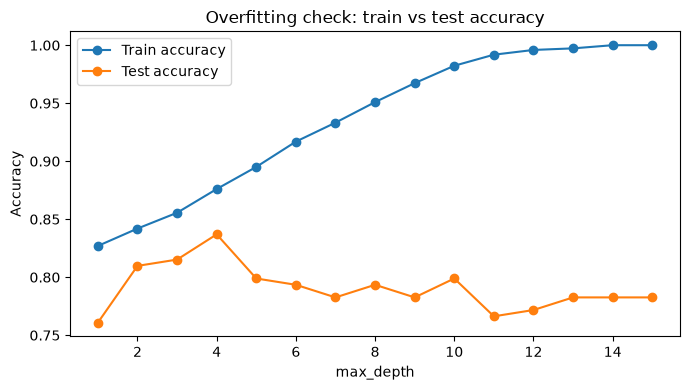

In [5]:
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting check: train vs test accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png")
plt.show()